**Exploratory notebook. Not meant to be run on its own.** It uses variables from the detrending notebook.
The reusable code is in `src/pipeline.py`, and the final analysis starts in `04_ephemeris.ipynb`.

In [1]:
#LOADING DATA

%matplotlib inline
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd

from cleaning import load_all_clean
from toi700_params import PLANETS

sectors_data = load_all_clean()
print(len(sectors_data), "sectors |",
      sum(len(d["time"]) for d in sectors_data), "points |",
      sum(d["n_removed"] for d in sectors_data), "removed")

/home/shantanu/anaconda3/envs/toi700/lib/python3.11/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


37 sectors | 589418 points | 114 removed


## Part 1: Analysing One Transit of Planet b In Sector 1

In [2]:
#Looking at Planet b

p = PLANETS["b"]
print(p)
print("period:", p["P"], "| first transit T0:", p["T0"], "| duration (hours):", p["T14_h"])

{'P': 9.97701, 'P_err': (0.00024, 0.00028), 'T0': 1331.3547, 'T0_err': (0.0048, 0.0032), 'T14_h': 2.15, 'T14_err': (0.15, 0.7), 'k': 0.0221, 'impact': 0.2, 'a_over_R': 34.8, 'Rp_earth': 1.01}
period: 9.97701 | first transit T0: 1331.3547 | duration (hours): 2.15


In [3]:
#half width of the transit

half = p["T14_h"] / 24 / 2
print("half-duration in days:", half)
print("half-duration in minutes:", half * 24 * 60)

half-duration in days: 0.04479166666666667
half-duration in minutes: 64.5


In [4]:
#looking at Sector 1

d = sectors_data[0]
t = d["time"]
print("sector:", d["sector"])
print("number of points:", len(t))
print("first time:", t.min(), "| last time:", t.max())

sector: 1
number of points: 18279
first time: 1325.2954950150029 | last time: 1353.1759744851113


In [5]:
#Predicting the transits of Planet b in Sector 1
x_lo = (t.min() - half - p["T0"]) / p["P"]
x_hi = (t.max() + half - p["T0"]) / p["P"]
print("x_lo:", x_lo)
print("x_hi:", x_hi)

#bringing it up to whole numbers because Transits cannot be fractional
n_lo = int(np.ceil(x_lo))
n_hi = int(np.floor(x_hi))
print("Total transits for Planet b in Sector 1 are: " , n_hi + 1 - n_lo )  # +1 in n_hi because we gotta count the 0th orbit too

x_lo: -0.6118062076377512
x_hi: 2.1916452075098536
Total transits for Planet b in Sector 1 are:  3


In [6]:
n = 0
tc = p["T0"] + n * p["P"]
print("predicted mid-transit time:", tc)

predicted mid-transit time: 1331.3547


In [7]:
#how far each data point is from Transit?

distance = np.abs(t - tc)
print("first 5 distances (days):", distance[:5])  #because the data stars aprrocimately 6 days before the first transit
print("closest point is", distance.min(), "days away")   

first 5 distances (days): [6.05920498 6.0578161  6.05642722 6.05503834 6.05364945]
closest point is 0.0005038312228862196 days away


In [8]:
#Number of points inside the transit

inside = distance < half
print("first 5 True/False values:", inside[:5])   #checking the first 5 points which i know are not inside the transit
print("points inside the transit:", inside.sum())


first 5 True/False values: [False False False False False]
points inside the transit: 64


In [9]:
# checking how complete is a transit

expected = 2 * half * 720
print("expected points for a complete transit:", expected)
print("fraction covered:", inside.sum() / expected)

expected points for a complete transit: 64.5
fraction covered: 0.9922480620155039


## Part 2: All Transits of Planet b in Sector 1

In [10]:
#calculating at which time the transit occuered for Planet b in Sector 1

for n in range(n_lo, n_hi + 1):
    tc = p["T0"] + n * p["P"]
    inside = np.abs(t - tc) < half
    print(f"n={n}  tc={tc:.3f}  points inside={inside.sum()}  fraction={inside.sum()/expected:.2f}")

#Basically doing the above calculation for all the 3 transits in Sector 1

n=0  tc=1331.355  points inside=64  fraction=0.99
n=1  tc=1341.332  points inside=65  fraction=1.01
n=2  tc=1351.309  points inside=61  fraction=0.95


In [11]:
#turning it into a table

rows = []
for n in range(n_lo, n_hi + 1):
    tc = p["T0"] + n * p["P"]
    inside = np.abs(t - tc) < half
    rows.append({"planet": "b", "sector": d["sector"], "epoch": n,
                 "tc": round(tc, 3), "frac": round(inside.sum() / expected, 2)})

table = pd.DataFrame(rows)
print(table)

  planet  sector  epoch        tc  frac
0      b       1      0  1331.355  0.99
1      b       1      1  1341.332  1.01
2      b       1      2  1351.309  0.95


## Part 3: All transits of Planet b in All sectors

In [12]:
rows = []
for d in sectors_data:
    t = d["time"]
    n_lo = int(np.ceil((t.min() - half - p["T0"]) / p["P"]))
    n_hi = int(np.floor((t.max() + half - p["T0"]) / p["P"]))
    n_in_sector = n_hi + 1 - n_lo
    for n in range(n_lo, n_hi + 1):
        tc = p["T0"] + n * p["P"]
        inside = np.abs(t - tc) < half
        rows.append({"planet": "b", "sector": d["sector"], "epoch": n,
                     "tc": round(tc, 3), "frac": round(inside.sum() / expected, 2), "n_in_sector": n_in_sector})

cov_b = pd.DataFrame(rows)
print(len(cov_b), "predicted transits of b") #includes the ones that are not part of observations, missing in gaps between the data

96 predicted transits of b


## Part 4: Creating a fucntion and doing it for all planets

In [13]:
#Making a function that can be used for all planets

def coverage(planet, sectors_data):
    p = PLANETS[planet]                          
    half = p["T14_h"] / 24 / 2                   
    expected = 2 * half * 720                    
    rows = []
    for d in sectors_data:                       
        t = d["time"]                            
        n_lo = int(np.ceil((t.min() - half - p["T0"]) / p["P"]))    
        n_hi = int(np.floor((t.max() + half - p["T0"]) / p["P"]))
        n_in_sector = n_hi + 1 - n_lo
        for n in range(n_lo, n_hi + 1):          
            tc = p["T0"] + n * p["P"]            
            inside = np.abs(t - tc) < half       
            rows.append({"planet": planet, "sector": d["sector"], "epoch": n,
                         "tc": round(tc, 3), "frac": round(inside.sum() / expected, 2), "n_in_sector": n_in_sector})
    return pd.DataFrame(rows)                    

cov_b2 = coverage("b", sectors_data)
print(cov_b2.equals(cov_b))    #checking if the table is same as previous convergance table

True


In [14]:
cov = pd.concat([coverage("b", sectors_data),
                 coverage("c", sectors_data),
                 coverage("d", sectors_data)], ignore_index=True)

for name in ["b", "c", "d"]:
    print(name, (cov["planet"] == name).sum(), "predicted transits")

#stacking tables for all 3 planets together, and the loop counts how many rows for each planet

b 96 predicted transits
c 54 predicted transits
d 26 predicted transits


In [15]:
tierA = {1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13}
cov["tierA"] = cov["sector"].isin(tierA)
print(cov.head(6).to_string(index=False))

#checking which sectors are in tier A (which is the previous published result sectors)

planet  sector  epoch       tc  frac  n_in_sector  tierA
     b       1      0 1331.355  0.99            3   True
     b       1      1 1341.332  1.01            3   True
     b       1      2 1351.309  0.95            3   True
     b       3      6 1391.217  0.98            2   True
     b       3      7 1401.194  1.01            2   True
     b       4      8 1411.171  0.99            3   True


In [16]:
#Checking for planet d, and its transits in sector Tier A

sub = cov[(cov["planet"] == "d") & (cov["tierA"])]
print(len(sub), "predicted transits of d in Tier A")
print(sub.to_string(index=False))
print("with fraction >= 0.5:", (sub["frac"] >= 0.5).sum())
print("with fraction >= 0.9:", (sub["frac"] >= 0.9).sum())

7 predicted transits of d in Tier A
planet  sector  epoch       tc  frac  n_in_sector  tierA
     d       1      0 1330.474  1.00            1   True
     d       3      2 1405.326  1.00            1   True
     d       5      3 1442.752  1.00            1   True
     d       6      4 1480.178  1.01            1   True
     d       9      6 1555.030  1.00            1   True
     d      10      7 1592.456  0.99            1   True
     d      13      9 1667.308  1.00            1   True
with fraction >= 0.5: 7
with fraction >= 0.9: 7


In [17]:
#This is just the cell above but for all planets

rows = []
for name in ["b", "c", "d"]:
    planet_rows = cov[cov["planet"] == name]
    tierA_rows = planet_rows[planet_rows["tierA"]]
    for label, sub in [("Tier A", tierA_rows), ("All", planet_rows)]:
        rows.append({"planet": name, "set": label, "predicted": len(sub),
                     "frac>=0.5": int((sub["frac"] >= 0.5).sum()),
                     "frac>=0.9": int((sub["frac"] >= 0.9).sum())})

print(pd.DataFrame(rows).to_string(index=False))

planet    set  predicted  frac>=0.5  frac>=0.9
     b Tier A         28         24         22
     b    All         96         83         81
     c Tier A         15         12         12
     c    All         54         47         47
     d Tier A          7          7          7
     d    All         26         24         23


## USING WOTAN

In [18]:
from wotan import flatten

d = sectors_data[0]
t = d["time"]
f = d["flux"]

print("median flux:", np.median(f))   # should be close to 1 because we have normalized it

# wotan is used to remove slow drifts due to various reasons like star moving, spacecraft pointing changing, etc
# and keeps the fast drifts, which are the transits

median flux: 1.0


In [19]:
flat, trend = flatten(t, f, method="biweight", window_length=0.6, break_tolerance=0.5, return_trend=True)

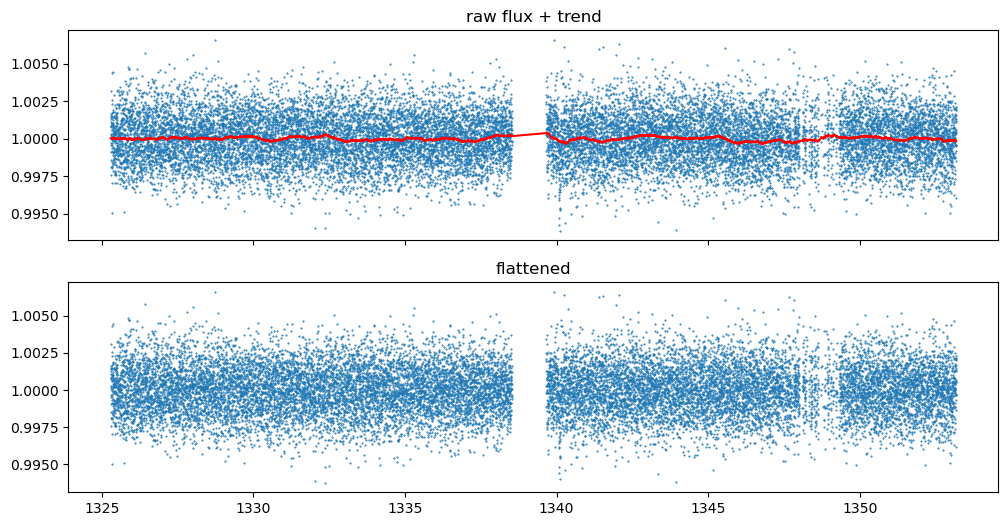

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(t, f, ".", ms=1)
ax[0].plot(t, trend, "r-")
ax[0].set_title("raw flux + trend")
ax[1].plot(t, flat, ".", ms=1)
ax[1].set_title("flattened")
plt.show()

In [21]:
# BUILDING A MASK
# which is basically telling wotan which points exist near the transit, 
# so as not to leave them out while estimating the trend

p = PLANETS["b"]
half = p["T14_h"] / 24 / 2
margin = 1.5                      # mask 1.5x wider than the transit

n_lo = int(np.ceil((t.min() - half - p["T0"]) / p["P"]))
n_hi = int(np.floor((t.max() + half - p["T0"]) / p["P"]))

mask = np.zeros(len(t), dtype=bool)     # start: nothing masked
for n in range(n_lo, n_hi + 1):
    tc = p["T0"] + n * p["P"]
    mask |= np.abs(t - tc) < half * margin

print("masked points:", mask.sum())   #from all 3 transits in sector 1

masked points: 286


In [22]:
#Detrending using only out of transit points

t_oot = t[~mask]           # ~mask means opposite of mask, i.e. everything outside the transits
f_oot = f[~mask]

flat_oot, trend_oot = flatten(t_oot, f_oot, method="biweight", window_length=0.6, break_tolerance=0.5, return_trend=True)

In [23]:
good = np.isfinite(trend_oot)                 # drop any NaN values
trend_masked = np.interp(t, t_oot[good], trend_oot[good])
flat_masked = f / trend_masked


# since we made a trend only the non transit values, we have a partially empty flux values in the flux array, this just fixes that

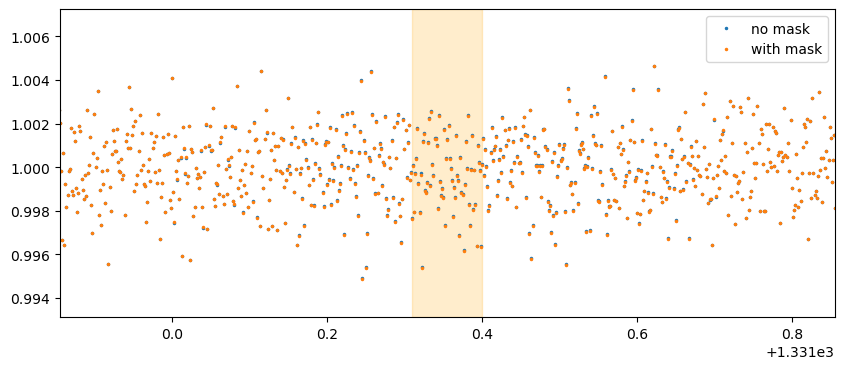

In [24]:
tc = p["T0"]     # first transit (n = 0) in sector 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, flat, ".", ms=3, label="no mask")
ax.plot(t, flat_masked, ".", ms=3, label="with mask")
ax.set_xlim(tc - 0.5, tc + 0.5)
ax.axvspan(tc - half, tc + half, alpha=0.2, color="orange")   #where the transit is supposed to be
ax.legend()
plt.show()

#comparing mask vs unmasked

In [25]:
#Checking the transit depth that survived

inside = np.abs(t - tc) < half
outside = ~mask

depth_unmasked = np.median(flat[outside]) - np.median(flat[inside])
depth_masked = np.median(flat_masked[outside]) - np.median(flat_masked[inside])

print("expected depth:", p["k"]**2)
print("no mask:  ", depth_unmasked)
print("with mask:", depth_masked)

expected depth: 0.0004884100000000001
no mask:   0.0003372941879873359
with mask: 0.00038377290125524155


In [26]:
#trying different window lengths

for window in [0.4, 0.5, 0.6, 0.75]:
    fl, tr = flatten(t_oot, f_oot, method="biweight", window_length=window,
                     break_tolerance=0.5, return_trend=True)
    good = np.isfinite(tr)
    trend_w = np.interp(t, t_oot[good], tr[good])
    flat_w = f / trend_w
    depth = np.median(flat_w[outside]) - np.median(flat_w[inside])
    print("window (h):", round(window * 24, 1), "| depth:", round(depth, 5))

window (h): 9.6 | depth: 0.0005
window (h): 12.0 | depth: 0.00045
window (h): 14.4 | depth: 0.00038
window (h): 18.0 | depth: 0.00038


## Now, applying it to all planets

In [27]:
#creating a mask function that works for all plaents

def make_mask(t, margin=1.5):
    mask = np.zeros(len(t), dtype=bool)
    for name in ["b", "c", "d"]:
        p = PLANETS[name]
        half = p["T14_h"] / 24 / 2
        n_lo = int(np.ceil((t.min() - half - p["T0"]) / p["P"]))
        n_hi = int(np.floor((t.max() + half - p["T0"]) / p["P"]))
        for n in range(n_lo, n_hi + 1):
            tc = p["T0"] + n * p["P"]
            pad = np.hypot(max(p["T0_err"]), abs(n) * max(p["P_err"]))   # hypot is √(a² + b²) for errors in T0 and P
            mask |= np.abs(t - tc) < half * margin + pad                 # it is added here as the n grows for later transits
    return mask                                                          # the predicted place of transit from actual transit 
                                                                         # will shift significantly
t = sectors_data[0]["time"]
print("masked points in sector 1:", make_mask(t).sum())

masked points in sector 1: 522


In [28]:
# detrending function for one sector

def detrend_sector(t, f, window, margin=1.5):
    mask = make_mask(t, margin)
    t_oot, f_oot = t[~mask], f[~mask]

    fl, tr = flatten(t_oot, f_oot, method="biweight", window_length=window,
                     break_tolerance=0.5, return_trend=True)

    good = np.isfinite(tr)
    trend = np.interp(t, t_oot[good], tr[good])
    return f / trend, trend, mask

flat, trend, mask = detrend_sector(t, sectors_data[0]["flux"], window=0.6)
print(len(t), len(flat), np.isnan(flat).sum())   # lengths equal, NaN count 0

18279 18279 0


In [29]:
# detrending every sector

detrended = []
for d in sectors_data:
    flat, trend, mask = detrend_sector(d["time"], d["flux"], window=0.6)
    detrended.append({"sector": d["sector"], "time": d["time"],
                      "flat": flat, "trend": trend, "mask": mask})

print(len(detrended), "sectors detrended")
print("NaN in flat:", sum(np.isnan(x["flat"]).sum() for x in detrended))

37 sectors detrended
NaN in flat: 0


In [30]:
#depth measurement

rows = []
for window in [0.4, 0.5, 0.6, 0.75]:
    for d in sectors_data:
        t, f = d["time"], d["flux"]
        flat, trend, mask = detrend_sector(t, f, window)
        outside = ~mask

        for name in ["b", "c", "d"]:
            p = PLANETS[name]
            half = p["T14_h"] / 24 / 2
            expected = 2 * half * 720
            n_lo = int(np.ceil((t.min() - half - p["T0"]) / p["P"]))
            n_hi = int(np.floor((t.max() + half - p["T0"]) / p["P"]))

            for n in range(n_lo, n_hi + 1):
                tc = p["T0"] + n * p["P"]
                inside = np.abs(t - tc) < half
                if inside.sum() < 0.9 * expected:      # skip transits with poor coverage
                    continue
                depth = np.median(flat[outside]) - np.median(flat[inside])
                rows.append({"window_h": round(window * 24, 1), "planet": name,
                             "sector": d["sector"], "epoch": n, "depth": depth})

depth_table = pd.DataFrame(rows)
print(len(depth_table), "depth measurements")

604 depth measurements


In [31]:
summary = depth_table.groupby(["planet", "window_h"])["depth"].agg(["count", "median", "std"])
summary["err"] = summary["std"] / np.sqrt(summary["count"])
print(summary.round(5))

for name in ["b", "c", "d"]:
    print(name, "expected depth (k^2):", round(PLANETS[name]["k"] ** 2, 5))

                 count   median      std      err
planet window_h                                  
b      9.6          81  0.00030  0.00035  0.00004
       12.0         81  0.00032  0.00032  0.00004
       14.4         81  0.00030  0.00030  0.00003
       18.0         81  0.00030  0.00030  0.00003
c      9.6          47  0.00201  0.00038  0.00005
       12.0         47  0.00196  0.00037  0.00005
       14.4         47  0.00197  0.00037  0.00005
       18.0         47  0.00197  0.00038  0.00006
d      9.6          23  0.00038  0.00045  0.00009
       12.0         23  0.00041  0.00046  0.00009
       14.4         23  0.00036  0.00045  0.00009
       18.0         23  0.00040  0.00043  0.00009
b expected depth (k^2): 0.00049
c expected depth (k^2): 0.00329
d expected depth (k^2): 0.00069


In [32]:
# Test 1 to check each planet’s transit still there at the depth we expect? 
# And are the paper’s predicted transit times still correct years later?

dt = depth_table[depth_table["window_h"] == 14.4].copy()
dt["tierA"] = dt["sector"].isin(tierA)

g = dt.groupby(["planet", "tierA"])["depth"].agg(["count", "median", "std"])
g["err"] = g["std"] / np.sqrt(g["count"])
print(g.round(5))

              count   median      std      err
planet tierA                                  
b      False     59  0.00027  0.00028  0.00004
       True      22  0.00042  0.00029  0.00006
c      False     35  0.00211  0.00038  0.00006
       True      12  0.00188  0.00035  0.00010
d      False     16  0.00019  0.00046  0.00012
       True       7  0.00070  0.00023  0.00009


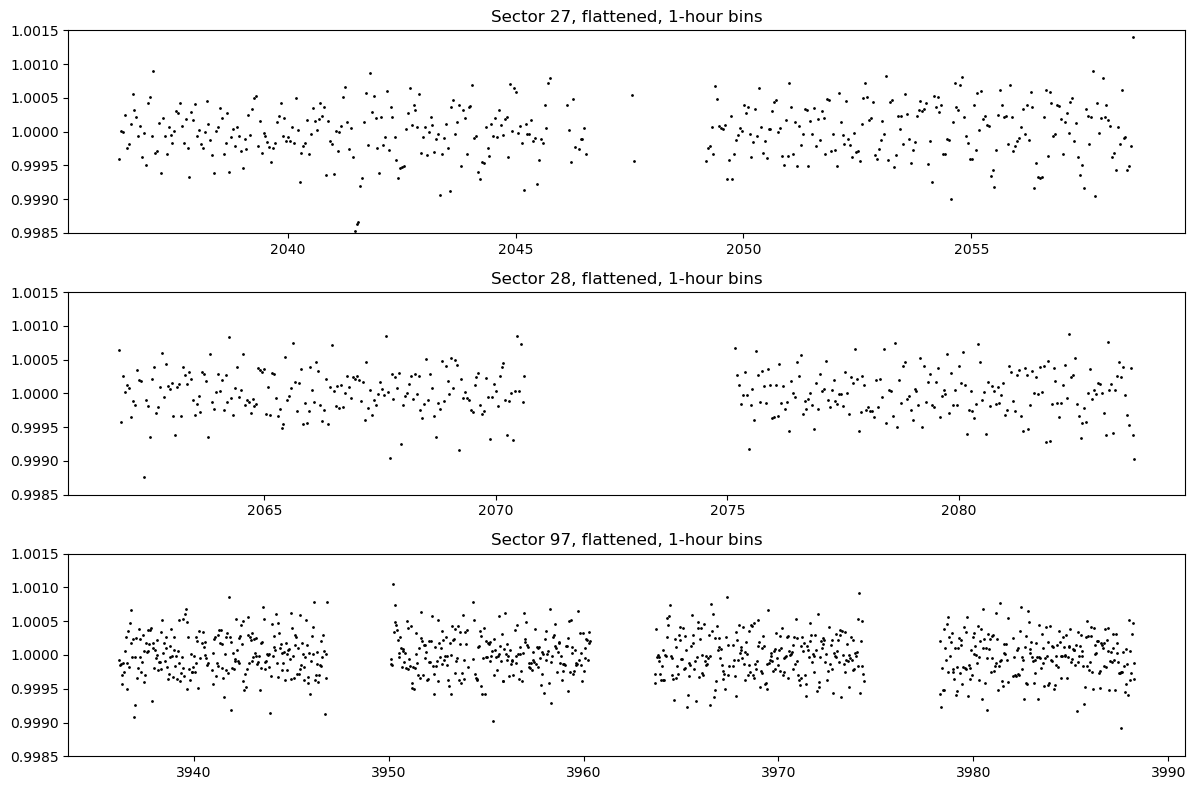

In [33]:
# Test 2: Is there any slow drifts left in the data
# After flattening, are there still slow waves or jumps, especially in the three sectors that showed waves before (27, 28 and the first orbit of 97)?

def hour_bins(t, y):
    idx = np.floor((t - t[0]) * 24).astype(int)       # which hour each point falls in
    hours = np.unique(idx)                            # the list of hours that have data
    tb = np.array([t[idx == h].mean() for h in hours])
    yb = np.array([y[idx == h].mean() for h in hours])
    return tb, yb

fig, axes = plt.subplots(3, 1, figsize=(12, 8))
for ax, s in zip(axes, [27, 28, 97]):
    x = detrended[[q["sector"] for q in detrended].index(s)]
    tb, yb = hour_bins(x["time"], x["flat"])
    ax.plot(tb, yb, ".", ms=2, color="k")
    ax.set_title(f"Sector {s}, flattened, 1-hour bins")
    ax.set_ylim(0.9985, 1.0015)
fig.tight_layout()
fig.savefig("../figures/flattened_27_28_97_1h.png", dpi=120)
plt.show()

In [34]:
print(PLANETS["c"])

{'P': 16.051098, 'P_err': (8.9e-05, 9.2e-05), 'T0': 1340.0887, 'T0_err': (0.0011, 0.001), 'T14_h': 1.41, 'T14_err': (0.14, 0.09), 'k': 0.0574, 'impact': 0.904, 'a_over_R': 47.8, 'Rp_earth': 2.63}


In [35]:
# Comparing 1-hour scatter with the white-noise expectation:

for s in [27, 28, 97]:
    x = detrended[[q["sector"] for q in detrended].index(s)]
    tb, yb = hour_bins(x["time"], x["flat"])
    print(s, "1-hour scatter (ppm):", round(np.std(yb) * 1e6),
          "| white-noise expectation:", round(np.std(x["flat"]) / np.sqrt(30) * 1e6))

27 1-hour scatter (ppm): 441 | white-noise expectation: 330
28 1-hour scatter (ppm): 358 | white-noise expectation: 315
97 1-hour scatter (ppm): 338 | white-noise expectation: 317


In [36]:


def robust_std(y):
    return 1.4826 * np.median(np.abs(y - np.median(y)))

x = detrended[[q["sector"] for q in detrended].index(27)]
tb, yb = hour_bins(x["time"], x["flat"])
print("1-hour (robust, ppm):", round(robust_std(yb) * 1e6),
      "| expectation (robust, ppm):", round(robust_std(x["flat"]) / np.sqrt(30) * 1e6))

1-hour (robust, ppm): 403 | expectation (robust, ppm): 328


### Preparing for BLS

In [37]:
# Stacking all sectors in one light curve

from astropy.timeseries import BoxLeastSquares

def robust_std(y):
    return 1.4826 * np.median(np.abs(y - np.median(y)))

t_list, f_list, dy_list = [], [], []
for x in detrended:
    ok = np.isfinite(x["flat"])                    # drop NaN values
    s = robust_std(x["flat"][ok])                  # noise level of THIS sector
    keep = ok & (x["flat"] < 1 + 4 * s)            # clip upward outliers (flares) only
    t_list.append(x["time"][keep])
    f_list.append(x["flat"][keep])
    dy_list.append(np.full(keep.sum(), s))         # one uncertainty per point

t_all = np.concatenate(t_list)                     #concantenate joins the arrays along a single axis
f_all = np.concatenate(f_list)
dy_all = np.concatenate(dy_list)

order = np.argsort(t_all)                          # put everything in time order
t_all, f_all, dy_all = t_all[order], f_all[order], dy_all[order]

baseline = t_all.max() - t_all.min()
print(len(t_all), "points | baseline (days):", round(baseline, 1))

589399 points | baseline (days): 2663.0


### BLS for planet c

In [38]:
# Choosing the planet and the box widths
# BLS fits a box, and it needs a width
# A real transit is not a perfect box, so the best-fitting box is often a bit narrower than T14. BLS keeps whichever width fits best.

name = "c"
p = PLANETS[name]

T14 = p["T14_h"] / 24                                   # published duration in days
durations = T14 * np.array([0.6, 0.8, 1.0, 1.2, 1.5])  # several box widths to try

print("published duration (h):", p["T14_h"])
print("box widths tried (h):", np.round(durations * 24, 2))

published duration (h): 1.41
box widths tried (h): [0.85 1.13 1.41 1.69 2.11]


In [39]:
#Creating a period grid

n_sigma = 20
half_range = n_sigma * max(p["P_err"])                  # search ±20 sigma around the paper's P
step = p["P"] * durations.min() / baseline / 3          # fine enough not to skip over a peak

periods = np.arange(p["P"] - half_range, p["P"] + half_range, step)
print(len(periods), "trial periods | range:", round(periods.min(), 5), "to", round(periods.max(), 5))
print("step (days):", step)

52 trial periods | range: 16.04926 to 16.05287
step (days): 7.082283164950113e-05


In [40]:
#Running the BLS

bls = BoxLeastSquares(t_all, f_all, dy=dy_all)
res = bls.power(periods, durations, objective="snr")
print("done")

done


In [41]:
i = np.argmax(res.power)                       # index of the strongest peak
P_best = res.period[i]

print("best period (d):", round(P_best, 6), "| published:", p["P"])
print("difference (d):", round(P_best - p["P"], 6),
      "| in units of published error:", round((P_best - p["P"]) / max(p["P_err"]), 1))
print("depth:", round(res.depth[i], 5), "+/-", round(res.depth_err[i], 5),
      "| expected k^2:", round(p["k"] ** 2, 5))
print("best box duration (h):", round(res.duration[i] * 24, 2), "| published T14 (h):", p["T14_h"])
print("SNR:", round(res.depth_snr[i], 1))

if i < 3 or i > len(periods) - 4:
    print("WARNING: peak is at the edge of the grid. Increase n_sigma and rerun Steps 3-5.")

best period (d): 16.051099 | published: 16.051098
difference (d): 1e-06 | in units of published error: 0.0
depth: 0.00242 +/- 4e-05 | expected k^2: 0.00329
best box duration (h): 1.1 | published T14 (h): 1.41
SNR: 57.8


In [42]:
tc_new = res.transit_time[i]                                  # BLS mid-transit time
n0 = np.round((tc_new - p["T0"]) / p["P"])                    # which published epoch that is
n_last = np.round((t_all.max() - p["T0"]) / p["P"])           # last epoch in the data

shift_first = tc_new - (p["T0"] + n0 * p["P"])
shift_last = (tc_new + (n_last - n0) * P_best) - (p["T0"] + n_last * p["P"])

print("timing shift, early data (min):", round(shift_first * 1440, 1))
print("timing shift, latest data (min):", round(shift_last * 1440, 1))
print("transit duration for comparison (min):", round(T14 * 1440))

timing shift, early data (min): -0.8
timing shift, latest data (min): -0.5
transit duration for comparison (min): 85


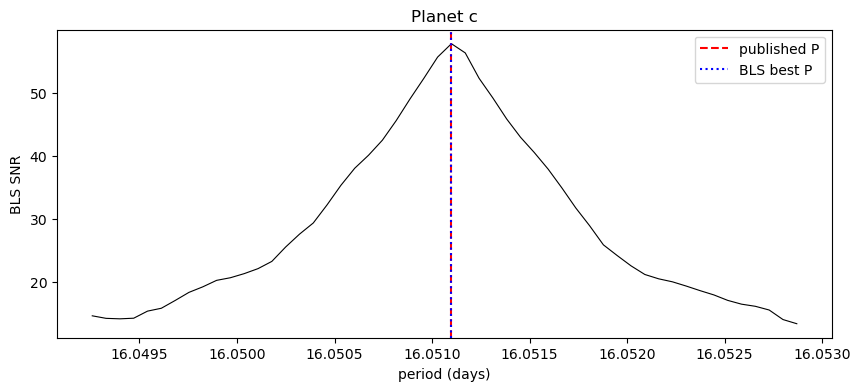

In [43]:
#Plots

plt.figure(figsize=(10, 4))
plt.plot(res.period, res.power, "k-", lw=0.8)
plt.axvline(p["P"], color="r", ls="--", label="published P")
plt.axvline(P_best, color="b", ls=":", label="BLS best P")
plt.xlabel("period (days)"); plt.ylabel("BLS SNR")
plt.title(f"Planet {name}"); plt.legend()
plt.savefig('../figures/planetc_newvsold_orbit.png', dpi = 120)
plt.show()

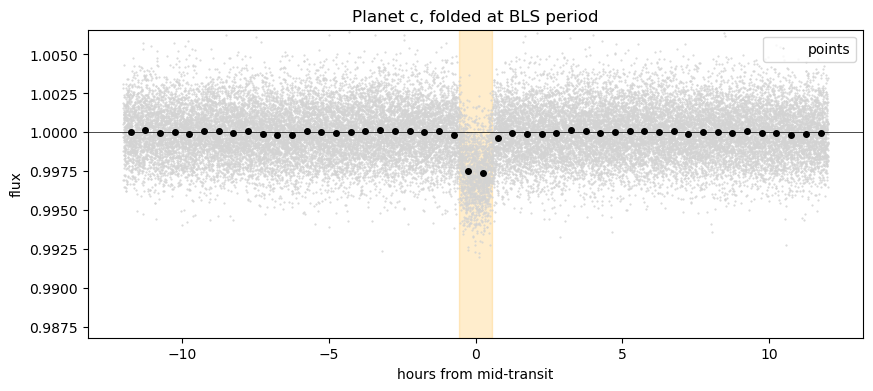

In [44]:
#Folding the data on the best period

half_window = 0.5                                              # days either side of transit
phase = ((t_all - tc_new + 0.5 * P_best) % P_best) - 0.5 * P_best   # days from mid-transit

sel = np.abs(phase) < half_window
ph, ff = phase[sel], f_all[sel]

bin_h = 0.5                                                    # 30-minute bins
edges = np.arange(-half_window, half_window + bin_h / 24, bin_h / 24)
counts, _ = np.histogram(ph, bins=edges)
sums, _ = np.histogram(ph, bins=edges, weights=ff)
centers = 0.5 * (edges[1:] + edges[:-1])
binned = np.where(counts > 0, sums / np.maximum(counts, 1), np.nan)
err = np.median(dy_all) / np.sqrt(np.maximum(counts, 1))

plt.figure(figsize=(10, 4))
plt.plot(ph * 24, ff, ".", ms=1, color="lightgray")
plt.errorbar(centers * 24, binned, yerr=err, fmt="ko", ms=4)
plt.axvspan(-res.duration[i] * 12, res.duration[i] * 12, alpha=0.2, color="orange")
plt.axhline(1, color="k", lw=0.5)
plt.ylim(1 - 4 * p["k"] ** 2, 1 + 2 * p["k"] ** 2)
plt.xlabel("hours from mid-transit"); plt.ylabel("flux")
plt.title(f"Planet {name}, folded at BLS period"); plt.legend(["points"], loc="upper right")
plt.show()

In [45]:
#Checking: Counting the transits and checking odd versus even

stats = bls.compute_stats(P_best, res.duration[i], tc_new)

print("transits with data:", int((stats["per_transit_count"] > 0).sum()))
print("odd-transit depth :", stats["depth_odd"])
print("even-transit depth:", stats["depth_even"])

transits with data: 47
odd-transit depth : (np.float64(0.0024394293110759913), np.float64(5.9870463585084255e-05))
even-transit depth: (np.float64(0.0024104815771988086), np.float64(5.8816548867665206e-05))


## Applying BLS to all 3 Planets

In [46]:
def run_bls(name, n_sigma=20):
    p = PLANETS[name]
    T14 = p["T14_h"] / 24
    durations = T14 * np.array([0.6, 0.8, 1.0, 1.2, 1.5])

    half_range = n_sigma * max(p["P_err"])
    step = p["P"] * durations.min() / baseline / 3
    periods = np.arange(p["P"] - half_range, p["P"] + half_range, step)

    bls = BoxLeastSquares(t_all, f_all, dy=dy_all)
    res = bls.power(periods, durations, objective="snr")
    i = np.argmax(res.power)

    P_best, tc_new = res.period[i], res.transit_time[i]
    n0 = np.round((tc_new - p["T0"]) / p["P"])
    n_last = np.round((t_all.max() - p["T0"]) / p["P"])
    shift_last = (tc_new + (n_last - n0) * P_best) - (p["T0"] + n_last * p["P"])

    return {"planet": name,
            "P_pub": p["P"], "P_bls": P_best,
            "dP_in_sigma": (P_best - p["P"]) / max(p["P_err"]),
            "depth": res.depth[i], "k2": p["k"] ** 2,
            "dur_bls_h": res.duration[i] * 24, "T14_h": p["T14_h"],
            "snr": res.depth_snr[i],
            "shift_end_min": shift_last * 1440,
            "edge": bool(i < 3 or i > len(periods) - 4),
            "res": res}

results = {name: run_bls(name) for name in ["c", "b", "d"]}

In [47]:
summary = pd.DataFrame([{k: v for k, v in r.items() if k != "res"} for r in results.values()])
print(summary.round(5).to_string(index=False))

planet    P_pub    P_bls  dP_in_sigma   depth      k2  dur_bls_h  T14_h      snr  shift_end_min  edge
     c 16.05110 16.05110      0.01515 0.00242 0.00329     1.0998   1.41 57.75186       -0.45005 False
     b  9.97701  9.97725      0.85689 0.00045 0.00049     2.1930   2.15 19.73463       85.75713 False
     d 37.42600 37.42367     -2.33044 0.00060 0.00069     3.2742   3.21 17.41274     -235.48138 False


In [48]:
def best_of(name):
    res = results[name]["res"]
    i = np.argmax(res.power)                     # index of the strongest peak
    return res, i, res.period[i], res.transit_time[i], res.duration[i]

In [49]:
def plot_periodogram(ax, name):
    p = PLANETS[name]
    res, i, P_best, tc_best, dur_best = best_of(name)

    ax.plot(res.period - p["P"], res.power, "k-", lw=0.8)
    ax.axvline(0, color="r", ls="--", label="published P")
    ax.axvline(P_best - p["P"], color="b", ls=":", label="BLS best P")
    ax.set_xlabel("period minus published period (days)")
    ax.set_ylabel("BLS SNR")
    ax.set_title(f"Planet {name}: periodogram")
    ax.legend()

In [50]:
def plot_fold(ax, name, half_window=0.5, bin_min=30, show_raw=False):
    p = PLANETS[name]
    res, i, P_best, tc_best, dur_best = best_of(name)

    # time from the nearest mid-transit (days), and flux as ppm relative to 1
    phase = ((t_all - tc_best + 0.5 * P_best) % P_best) - 0.5 * P_best
    sel = np.abs(phase) < half_window
    ph, ff = phase[sel], (f_all[sel] - 1) * 1e6

    # average the points into bins
    edges = np.arange(-half_window, half_window + bin_min / 1440, bin_min / 1440)
    counts, _ = np.histogram(ph, bins=edges)
    sums, _ = np.histogram(ph, bins=edges, weights=ff)
    centers = 0.5 * (edges[1:] + edges[:-1])
    ok = counts > 0
    binned = sums[ok] / counts[ok]
    err = np.median(dy_all) * 1e6 / np.sqrt(counts[ok])

    # plotting
    if show_raw:
        ax.plot(ph * 24, ff, ".", ms=1, color="lightgray", zorder=0)
    ax.errorbar(centers[ok] * 24, binned, yerr=err, fmt="ko", ms=4, zorder=3)
    ax.axvspan(-dur_best * 12, dur_best * 12, alpha=0.2, color="orange")
    ax.axhline(0, color="k", lw=0.5)
    ax.axhline(-p["k"] ** 2 * 1e6, color="r", ls="--", lw=1, label="expected depth (k$^2$)")
    ax.hlines(-res.depth[i] * 1e6, -dur_best * 12, dur_best * 12,
              color="b", lw=2, label="BLS depth")

    # zoom to the binned data (and the expected depth), not to the raw scatter
    lo = min((binned - err).min(), -p["k"] ** 2 * 1e6)
    hi = (binned + err).max()
    pad = 0.15 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)

    ax.set_xlabel("hours from mid-transit")
    ax.set_ylabel("flux - 1 (ppm)")
    ax.set_title(f"Planet {name}: folded at BLS period")
    ax.legend(fontsize=8, loc="lower right")

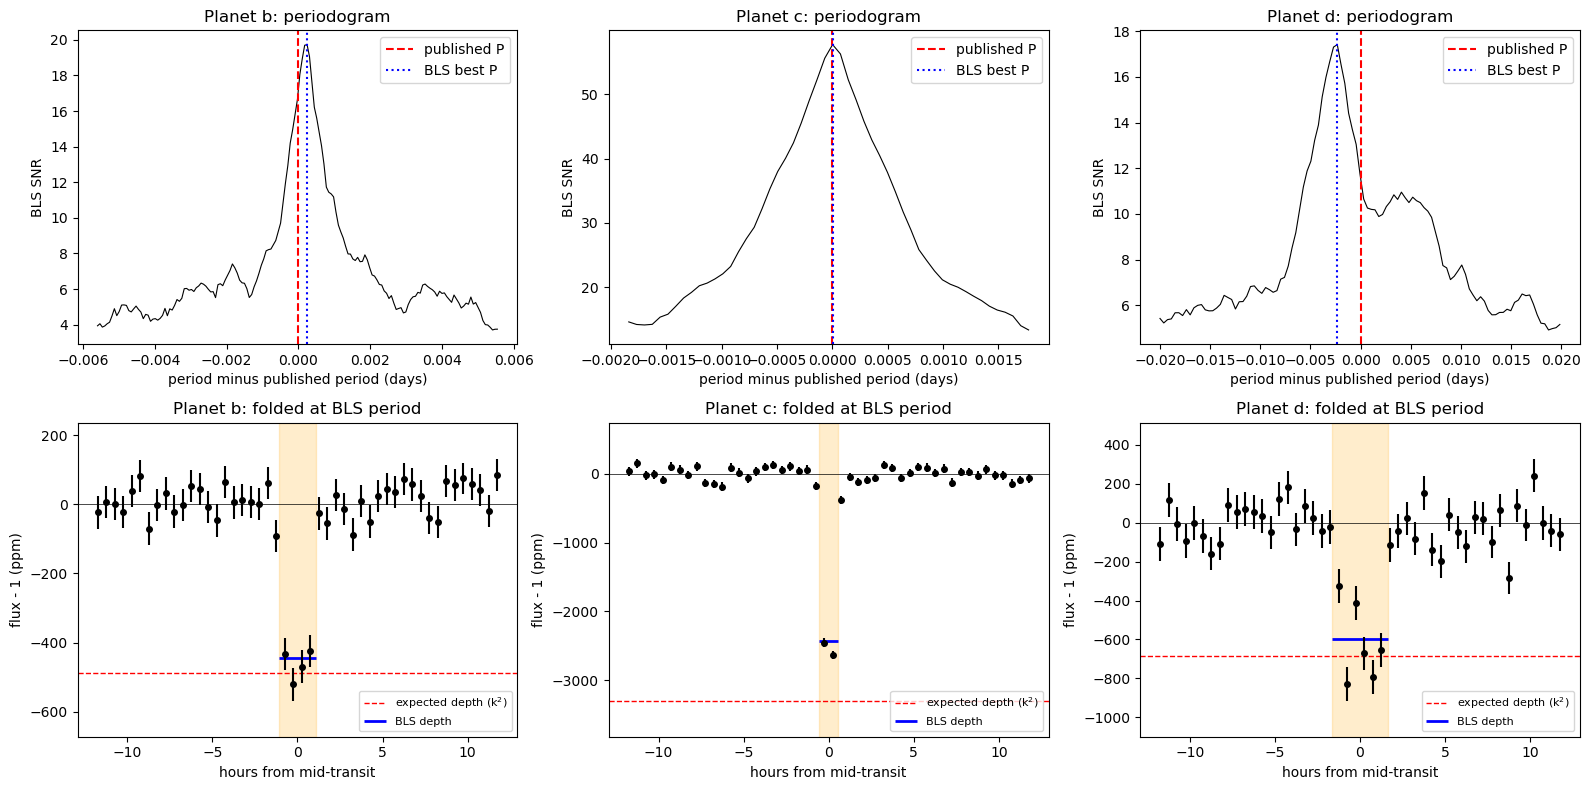

In [51]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for col, name in enumerate(["b", "c", "d"]):
    plot_periodogram(axes[0, col], name)    # top row: periodograms
    plot_fold(axes[1, col], name)           # bottom row: folded transits

fig.tight_layout()
fig.savefig("../figures/bls_all_planets.png", dpi=120)
plt.show()

In [52]:
bls_obj = BoxLeastSquares(t_all, f_all, dy=dy_all)
rows = []

for name in ["b", "c", "d"]:
    p = PLANETS[name]
    r = results[name]
    res, i, P_best, tc_best, dur_best = best_of(name)
    stats = bls_obj.compute_stats(P_best, dur_best, tc_best)

    rows.append({
        "planet": name,
        "P_published_d": p["P"],
        "P_published_err_d": max(p["P_err"]),
        "P_bls_d": P_best,
        "dP_d": P_best - p["P"],
        "dP_in_sigma": r["dP_in_sigma"],
        "T0_bls_BTJD": tc_best,
        "duration_bls_h": dur_best * 24,
        "duration_published_h": p["T14_h"],
        "depth_bls": res.depth[i],
        "depth_bls_err": res.depth_err[i],
        "depth_expected_k2": p["k"] ** 2,
        "snr": res.depth_snr[i],
        "timing_shift_end_min": r["shift_end_min"],
        "n_transits_with_data": int((stats["per_transit_count"] > 0).sum()),
        "depth_odd": stats["depth_odd"][0],
        "depth_even": stats["depth_even"][0],
        "peak_at_grid_edge": r["edge"],
    })

bls_table = pd.DataFrame(rows)
print(bls_table.round(6).T)          # transposed so the long column names are readable

                                0            1            2
planet                          b            c            d
P_published_d             9.97701    16.051098       37.426
P_published_err_d         0.00028     0.000092        0.001
P_bls_d                   9.97725    16.051099     37.42367
dP_d                      0.00024     0.000001     -0.00233
dP_in_sigma              0.856888     0.015148     -2.33044
T0_bls_BTJD           1331.350433  1340.088158  1330.475633
duration_bls_h              2.193       1.0998       3.2742
duration_published_h         2.15         1.41         3.21
depth_bls                0.000445     0.002425     0.000599
depth_bls_err            0.000023     0.000042     0.000034
depth_expected_k2        0.000488     0.003295     0.000686
snr                     19.734626    57.751856     17.41274
timing_shift_end_min    85.757126    -0.450054  -235.481379
n_transits_with_data           83           47           25
depth_odd                0.000472     0.

In [53]:
bls_table.to_csv("../data/bls_results.csv", index=False)
print("saved", len(bls_table), "rows")

saved 3 rows


In [54]:
#Saving the periodograms themselves, saving the raw curves, to replot or share them later without rerunning BLS

for name in ["b", "c", "d"]:
    res = results[name]["res"]
    pd.DataFrame({"period": res.period, "power": res.power,
                  "depth": res.depth, "duration": res.duration}
                 ).to_csv(f"../data/bls_periodogram_{name}.csv", index=False)

## Calculating Uncertainities


Using a Bootstrap Method: We will be drawing 37 sectors randomly, and some might not get picket and some might get picket twice, sun BLS over them, and see how much the period values shifts in each case. Each fake data set is a different “what if the sky had given us a slightly different mix of observations” scenario. Based on this, if the values shift a lot, then the value depends on each sector's data and if it is consistent, then we are close to the original value.

In [55]:
#Step 1: Running the BLS, but shifting the period by 1 min, and grid spans ±45 minutes

name = "b"
p = PLANETS[name]
res_p, i_p, P0, tc0, dur0 = best_of(name)       # pass-1 BLS result for this planet

n_epochs = baseline / P0                         # orbits across the whole data span
dP = (1 / 1440) / n_epochs                       # period change that moves the LAST transit by 1 minute

shifts = np.arange(-45, 46)                      # -45 ... +45 minutes at the end of the data
periods_fine = P0 + shifts * dP

print("step (d):", dP, "| trial periods:", len(periods_fine))

step (d): 2.6018306960416196e-06 | trial periods: 91


In [56]:
#Step 2: Finding best period of any set of sectors

def best_period(idx, oversample=100):
    t = np.concatenate([t_list[j] for j in idx])
    f = np.concatenate([f_list[j] for j in idx])
    dy = np.concatenate([dy_list[j] for j in idx])
    o = np.argsort(t)
    t, f, dy = t[o], f[o], dy[o]

    bls = BoxLeastSquares(t, f, dy=dy)
    r = bls.power(periods_fine, dur0, objective="likelihood", oversample=oversample)
    return periods_fine[np.argmax(r.power)]

In [57]:
#Step 3: How much time will it take

import time
t0 = time.time()
test = best_period(np.arange(len(t_list)))        # all sectors, once
print("one run took (s):", round(time.time() - t0, 1), "| best P:", test)

one run took (s): 0.3 | best P: 9.977210901280296


In [58]:
#Step 4: Running the Bootstrap

rng = np.random.default_rng(42)                   # fixed seed, so the result is reproducible
n_sectors = len(t_list)
n_boot = 200

boot = []
for k in range(n_boot):
    idx = rng.integers(0, n_sectors, n_sectors)   # sectors drawn WITH replacement
    boot.append(best_period(idx))
boot = np.array(boot)
print("done:", len(boot), "resamples")

done: 200 resamples


In [59]:
#Step 5: Turning the spread into period and uncertainity

P_med = np.median(boot)
lo, hi = np.percentile(boot, [16, 84])            # the middle 68% = 1 sigma
err = (hi - lo) / 2

print("period:", round(P_med, 6), "+/-", round(err, 6))
print("published error:", max(p["P_err"]))
print("improvement factor:", round(max(p["P_err"]) / err, 1))
print("error in grid steps:", round(err / dP, 1))

period: 9.977214 +/- 2.3e-05
published error: 0.00028
improvement factor: 12.0
error in grid steps: 9.0


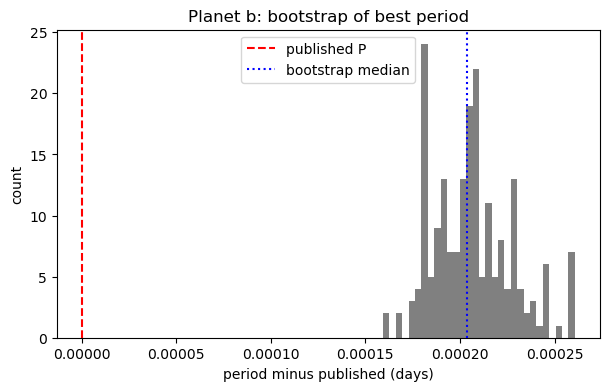

In [60]:
#Step 6: Looking at the distribution

plt.figure(figsize=(7, 4))
plt.hist(boot - p["P"], bins=30, color="gray")
plt.axvline(0, color="r", ls="--", label="published P")
plt.axvline(P_med - p["P"], color="b", ls=":", label="bootstrap median")
plt.xlabel("period minus published (days)"); plt.ylabel("count")
plt.title(f"Planet {name}: bootstrap of best period"); plt.legend()
plt.show()

In [61]:
#Step 7: For all planets

def bootstrap_period(name, n_boot=200, oversample=100, seed=42):
    p = PLANETS[name]
    res_p, i_p, P0, tc0, dur0 = best_of(name)
    dP = (1 / 1440) / (baseline / P0)
    grid = P0 + np.arange(-45, 46) * dP

    def one_run(idx):
        t = np.concatenate([t_list[j] for j in idx])
        f = np.concatenate([f_list[j] for j in idx])
        dy = np.concatenate([dy_list[j] for j in idx])
        o = np.argsort(t)
        r = BoxLeastSquares(t[o], f[o], dy=dy[o]).power(
            grid, dur0, objective="likelihood", oversample=oversample)
        return grid[np.argmax(r.power)]

    rng = np.random.default_rng(seed)
    n = len(t_list)
    boot = np.array([one_run(rng.integers(0, n, n)) for _ in range(n_boot)])
    P_all = one_run(np.arange(n))
    lo, hi = np.percentile(boot, [16, 84])
    err = (hi - lo) / 2
    return {"planet": name, "P_all_data": P_all, "P_boot_median": np.median(boot),
            "err_boot": err, "err_in_steps": err / dP,
            "P_pub": p["P"], "err_pub": max(p["P_err"]),
            "improvement_factor": max(p["P_err"]) / err if err > 0 else np.nan,
            "offset_from_pub_in_pub_sigma": (P_all - p["P"]) / max(p["P_err"]),
            "boot": boot}

boot_results = {name: bootstrap_period(name) for name in ["b", "c", "d"]}

boot_table = pd.DataFrame([{k: v for k, v in r.items() if k != "boot"}
                           for r in boot_results.values()])
print(boot_table.round(7).to_string(index=False))
boot_table.to_csv("../data/bls_period_bootstrap.csv", index=False)

planet  P_all_data  P_boot_median  err_boot  err_in_steps     P_pub  err_pub  improvement_factor  offset_from_pub_in_pub_sigma
     b    9.977211       9.977213  0.000023          9.00  9.977010 0.000280           11.957393                      0.717505
     c   16.051120      16.051112  0.000013          3.00 16.051098 0.000092            7.326450                      0.242634
     d   37.423631      37.423552  0.000093          9.58 37.426000 0.001000           10.695964                     -2.369477


In [62]:
#Check 1: Any resample hitting the edge of the grid?

for name, r in boot_results.items():
    b = r["boot"]
    P0 = best_of(name)[2]
    dP = (1 / 1440) / (baseline / P0)
    lo_edge, hi_edge = P0 - 45 * dP, P0 + 45 * dP
    at_edge = np.sum((b <= lo_edge + dP) | (b >= hi_edge - dP))
    print(name, "| boot min/max:", round(b.min(), 6), round(b.max(), 6),
          "| at edge:", at_edge, "of", len(b))

b | boot min/max: 9.977169 9.977271 | at edge: 0 of 200
c | boot min/max: 16.051074 16.051137 | at edge: 0 of 200
d | boot min/max: 37.42323 37.424021 | at edge: 1 of 200


In [63]:
#Check 2: How often d's 2nd bump wins

def bootstrap_wide(name, n_boot=100, half_range=0.02, step=1e-4, seed=7):
    res_p, i_p, P0, tc0, dur0 = best_of(name)
    grid = np.arange(P0 - half_range, P0 + half_range, step)
    rng = np.random.default_rng(seed)
    n = len(t_list)
    out = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        t = np.concatenate([t_list[j] for j in idx])
        f = np.concatenate([f_list[j] for j in idx])
        dy = np.concatenate([dy_list[j] for j in idx])
        o = np.argsort(t)
        r = BoxLeastSquares(t[o], f[o], dy=dy[o]).power(
            grid, dur0, objective="likelihood", oversample=20)
        out.append(grid[np.argmax(r.power)])
    return P0, np.array(out)

P0, wide = bootstrap_wide("d")
main = np.abs(wide - P0) < 0.001
print("resamples on the main peak:", main.sum(), "of", len(wide))
print("others (offset from main, d):", np.round(np.sort(wide[~main]) - P0, 4))

resamples on the main peak: 100 of 100
others (offset from main, d): []


## PASS 2 
Pass 1 marked transits with the paper's given values, Pass 2 is doing this with our new found values, then running wotan and bls from these new values

### Part A: New ephemerides

In [64]:
#Step 1: Keep a copy of pass 1

pass1 = {"detrended": detrended, "results": results, "boot_results": boot_results,
         "t_list": t_list, "f_list": f_list, "dy_list": dy_list,
         "t_all": t_all, "f_all": f_all, "dy_all": dy_all, "baseline": baseline}

In [65]:
#Step 2: Finding the T0 for each new period

def t0_at_period(name, P_new):
    res_p, i_p, P0, tc0, dur0 = best_of(name)
    r = BoxLeastSquares(t_all, f_all, dy=dy_all).power(
        np.array([P_new]), dur0, objective="likelihood", oversample=200)
    return r.transit_time[0], dur0

In [66]:
#Step 3: Building the Ephemeris table

inflate = 1.5                                      # widen errors by 50% for a safer mask
t_mid = 0.5 * (t_all.max() + t_all.min())

EPH = {}
for name in ["b", "c", "d"]:
    P_new = boot_results[name]["P_all_data"]
    tc, _ = t0_at_period(name, P_new)
    n_mid = np.round((t_mid - tc) / P_new)         # move T0 to the middle of the data
    EPH[name] = {"P": P_new,
                 "P_err": inflate * boot_results[name]["err_boot"],
                 "T0": tc + n_mid * P_new,
                 "T14_h": PLANETS[name]["T14_h"]}
    print(name, EPH[name])

b {'P': np.float64(9.977210901280296), 'P_err': np.float64(3.5124714395706746e-05), 'T0': np.float64(2658.321793635282), 'T14_h': 2.15}
c {'P': np.float64(16.05112032235745), 'P_err': np.float64(1.883586111617319e-05), 'T0': np.float64(2656.2782966983136), 'T14_h': 1.41}
d {'P': np.float64(37.423630523022815), 'P_err': np.float64(0.00014023981160882215), 'T0': np.float64(2640.3080775708013), 'T14_h': 3.21}


In [67]:
for name in ["b", "c", "d"]:
    e, p = EPH[name], PLANETS[name]
    new_last = e["T0"] + np.round((t_all.max() - e["T0"]) / e["P"]) * e["P"]
    old_last = p["T0"] + np.round((new_last - p["T0"]) / p["P"]) * p["P"]
    print(name, "new minus old prediction, last transit (min):", round((new_last - old_last) * 1440, 1))

b new minus old prediction, last transit (min): 74.1
c new minus old prediction, last transit (min): 2.0
d new minus old prediction, last transit (min): -231.7


### Part B: New Masks and Detrending

In [68]:
#Step 5: Mask function using the new ephemerides

def make_mask2(t, margin=1.5, t0_pad=0.01):
    mask = np.zeros(len(t), dtype=bool)
    for name in ["b", "c", "d"]:
        e = EPH[name]
        half = e["T14_h"] / 24 / 2
        n_lo = int(np.ceil((t.min() - half - e["T0"]) / e["P"]))
        n_hi = int(np.floor((t.max() + half - e["T0"]) / e["P"]))
        for n in range(n_lo, n_hi + 1):
            tc = e["T0"] + n * e["P"]
            pad = np.hypot(t0_pad, abs(n) * e["P_err"])
            mask |= np.abs(t - tc) < half * margin + pad
    return mask

In [69]:
#Step 6: Detrend one sector with the new mask

def detrend_sector2(t, f, window=0.6, margin=1.5):
    mask = make_mask2(t, margin)
    t_oot, f_oot = t[~mask], f[~mask]
    fl, tr = flatten(t_oot, f_oot, method="biweight", window_length=window,
                     break_tolerance=0.5, return_trend=True)
    good = np.isfinite(tr)
    trend = np.interp(t, t_oot[good], tr[good])
    return f / trend, trend, mask

In [70]:
#Step 7: Detrend every sector and compare masks

detrended2 = []
for d in sectors_data:
    flat, trend, mask = detrend_sector2(d["time"], d["flux"])
    detrended2.append({"sector": d["sector"], "time": d["time"],
                       "flat": flat, "trend": trend, "mask": mask})

m1 = np.concatenate([x["mask"] for x in detrended])
m2 = np.concatenate([x["mask"] for x in detrended2])
print("masked fraction, pass 1 / pass 2:", round(m1.mean(), 4), round(m2.mean(), 4))
print("pass-2 masked points that were NOT masked in pass 1:", int((m2 & ~m1).sum()))
print("NaN in flat:", sum(np.isnan(x["flat"]).sum() for x in detrended2))

masked fraction, pass 1 / pass 2: 0.0342 0.0281
pass-2 masked points that were NOT masked in pass 1: 1202
NaN in flat: 0


### Part C: Repeat Test 1

In [71]:
#Step 8: Per-transit depths with the new ephemerides

rows = []
for d2 in detrended2:
    t, flat, mask = d2["time"], d2["flat"], d2["mask"]
    outside = ~mask
    for name in ["b", "c", "d"]:
        e = EPH[name]
        half = e["T14_h"] / 24 / 2
        expected = 2 * half * 720                       # points in a full transit (2-min cadence)
        n_lo = int(np.ceil((t.min() - half - e["T0"]) / e["P"]))
        n_hi = int(np.floor((t.max() + half - e["T0"]) / e["P"]))
        for n in range(n_lo, n_hi + 1):
            tc = e["T0"] + n * e["P"]
            inside = np.abs(t - tc) < half
            if inside.sum() < 0.9 * expected:
                continue
            depth = np.median(flat[outside]) - np.median(flat[inside])
            rows.append({"planet": name, "sector": d2["sector"], "epoch": n, "depth": depth})

depth_table2 = pd.DataFrame(rows)
depth_table2["tierA"] = depth_table2["sector"].isin(tierA)

g2 = depth_table2.groupby(["planet", "tierA"])["depth"].agg(["count", "median", "std"])
g2["err"] = g2["std"] / np.sqrt(g2["count"])
print(g2.round(5))

              count   median      std      err
planet tierA                                  
b      False     58  0.00041  0.00030  0.00004
       True      22  0.00053  0.00028  0.00006
c      False     35  0.00211  0.00039  0.00007
       True      12  0.00197  0.00034  0.00010
d      False     15  0.00045  0.00038  0.00010
       True       7  0.00066  0.00027  0.00010


### Part D: Rerun BLS and the bootstrap on pass-2 data

In [72]:
#Step 9: Stack the pass-2 data and swap it into the working names

def stack(det):
    t_l, f_l, dy_l = [], [], []
    for x in det:
        ok = np.isfinite(x["flat"])
        s = robust_std(x["flat"][ok])
        keep = ok & (x["flat"] < 1 + 4 * s)
        t_l.append(x["time"][keep]); f_l.append(x["flat"][keep])
        dy_l.append(np.full(keep.sum(), s))
    t, f, dy = np.concatenate(t_l), np.concatenate(f_l), np.concatenate(dy_l)
    o = np.argsort(t)
    return t_l, f_l, dy_l, t[o], f[o], dy[o]

t_list, f_list, dy_list, t_all, f_all, dy_all = stack(detrended2)
baseline = t_all.max() - t_all.min()
print(len(t_all), "points | baseline:", round(baseline, 1))

589399 points | baseline: 2663.0


In [73]:
results = {name: run_bls(name) for name in ["c", "b", "d"]}
print(pd.DataFrame([{k: v for k, v in r.items() if k != "res"} for r in results.values()]).round(5).to_string(index=False))

planet    P_pub    P_bls  dP_in_sigma   depth      k2  dur_bls_h  T14_h      snr  shift_end_min  edge
     c 16.05110 16.05110      0.01515 0.00242 0.00329     1.0998   1.41 57.69471       -0.45005 False
     b  9.97701  9.97725      0.85689 0.00045 0.00049     2.1930   2.15 19.90171       85.75713 False
     d 37.42600 37.42367     -2.33044 0.00064 0.00069     3.2742   3.21 18.72786     -235.48138 False


In [74]:
boot_results2 = {name: bootstrap_period(name) for name in ["b", "c", "d"]}

### Part E: Compare and save

In [75]:
#Step 12: Pass 1 versus pass 2

rows = []
for name in ["b", "c", "d"]:
    r1, r2 = pass1["results"][name], results[name]
    b1, b2 = pass1["boot_results"][name], boot_results2[name]
    rows.append({"planet": name,
                 "P_pass1": b1["P_all_data"], "err_pass1": b1["err_boot"],
                 "P_pass2": b2["P_all_data"], "err_pass2": b2["err_boot"],
                 "dP_in_pass1_sigma": (b2["P_all_data"] - b1["P_all_data"]) / b1["err_boot"],
                 "depth_pass1": r1["depth"], "depth_pass2": r2["depth"],
                 "snr_pass1": r1["snr"], "snr_pass2": r2["snr"],
                 "depth_over_k2_pass2": r2["depth"] / r2["k2"]})

comparison = pd.DataFrame(rows)
print(comparison.round(6).T)
comparison.to_csv("../data/bls_pass1_vs_pass2.csv", index=False)

                             0          1          2
planet                       b          c          d
P_pass1               9.977211   16.05112  37.423631
err_pass1             0.000023   0.000013   0.000093
P_pass2               9.977211   16.05112  37.423631
err_pass2             0.000022   0.000013   0.000093
dP_in_pass1_sigma          0.0        0.0        0.0
depth_pass1           0.000445   0.002425   0.000599
depth_pass2           0.000449   0.002423   0.000645
snr_pass1            19.734626  57.751856   17.41274
snr_pass2            19.901708  57.694711  18.727856
depth_over_k2_pass2   0.919578   0.735494   0.939375


In [76]:
#Step 13: Save the final ephemerides

final = []
for name in ["b", "c", "d"]:
    P_new = boot_results2[name]["P_all_data"]
    tc, _ = t0_at_period(name, P_new)
    n_mid = np.round((t_mid - tc) / P_new)
    final.append({"planet": name, "P_d": P_new, "P_err_d": boot_results2[name]["err_boot"],
                  "T0_BTJD_mid_data": tc + n_mid * P_new})

final_eph = pd.DataFrame(final)
print(final_eph.round(7).to_string(index=False))
final_eph.to_csv("../data/ephemerides_pass2.csv", index=False)

planet       P_d  P_err_d  T0_BTJD_mid_data
     b  9.977211 0.000022       2658.321794
     c 16.051120 0.000013       2656.278297
     d 37.423631 0.000093       2640.308078


In [77]:
#Finding Uncertainity on T0 and P, also using a finer step for c

def bootstrap_ephemeris(name, n_boot=200, oversample=100, step_min=1.0, seed=42):
    res_p, i_p, P0, tc0, dur0 = best_of(name)
    dP = (step_min / 1440) / (baseline / P0)          # period step that moves the last transit by step_min minutes
    n_steps = int(round(45 / step_min))               # grid always spans +/- 45 minutes at the end of the data
    grid = P0 + np.arange(-n_steps, n_steps + 1) * dP

    rng = np.random.default_rng(seed)
    n = len(t_list)
    P_out, T0_out = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)                   # draw sectors with replacement
        t = np.concatenate([t_list[j] for j in idx])
        f = np.concatenate([f_list[j] for j in idx])
        dy = np.concatenate([dy_list[j] for j in idx])
        o = np.argsort(t)
        r = BoxLeastSquares(t[o], f[o], dy=dy[o]).power(
            grid, dur0, objective="likelihood", oversample=oversample)
        k = np.argmax(r.power)
        P_k, tc_k = grid[k], r.transit_time[k]
        T0_out.append(tc_k + np.round((t_mid - tc_k) / P_k) * P_k)   # move T0 to the middle of the data
        P_out.append(P_k)
    return np.array(P_out), np.array(T0_out)

def summarize(x):
    lo, hi = np.percentile(x, [16, 84])
    return np.median(x), (hi - lo) / 2

for name, step in [("b", 1.0), ("c", 0.25), ("d", 1.0)]:
    P_s, T0_s = bootstrap_ephemeris(name, step_min=step)
    print(name, "P:", summarize(P_s), "| T0:", summarize(T0_s))

b P: (np.float64(9.977213503110992), np.float64(2.232370737154099e-05)) | T0: (np.float64(2658.32283176573), np.float64(0.0015780534959048964))
c P: (np.float64(16.051109334771795), np.float64(1.151080401662341e-05)) | T0: (np.float64(2656.2789424031744), np.float64(0.0005774592259513156))
d P: (np.float64(37.42355732896665), np.float64(9.349320773921477e-05)) | T0: (np.float64(2640.309606346831), np.float64(0.0028423835981357115))


In [78]:
#Comparison Table

lit = {
    "b": {"P2020": 9.97701,   "e2020": 0.00028,  "P2023": 9.977219, "e2023": 0.000041},
    "c": {"P2020": 16.051098, "e2020": 0.000092, "P2023": 16.051137, "e2023": 0.000020},
    "d": {"P2020": 37.4260,   "e2020": 0.0010,   "P2023": 37.42396, "e2023": 0.00039},
}

rows = []
for name in ["b", "c", "d"]:
    L = lit[name]
    P_new = boot_results2[name]["P_all_data"]
    e_new = boot_results2[name]["err_boot"]
    rows.append({
        "planet": name,
        "P_this_work": P_new, "err_this_work": e_new,
        "diff_vs_2020_sigma": (P_new - L["P2020"]) / np.hypot(e_new, L["e2020"]),
        "diff_vs_2023_sigma": (P_new - L["P2023"]) / np.hypot(e_new, L["e2023"]),
        "gain_vs_2020": L["e2020"] / e_new,
        "gain_vs_2023": L["e2023"] / e_new,
    })

lit_table = pd.DataFrame(rows)
print(lit_table.round(4).T)
lit_table.to_csv("../data/period_comparison_2020_2023.csv", index=False)

                          0        1        2
planet                    b        c        d
P_this_work          9.9772  16.0511  37.4236
err_this_work           0.0      0.0   0.0001
diff_vs_2020_sigma   0.7152   0.2404  -2.3592
diff_vs_2023_sigma  -0.1735  -0.7062  -0.8215
gain_vs_2020        12.5427   7.3265   10.696
gain_vs_2023         1.8366   1.5927   4.1714


In [80]:
#Saving pass-2 data

import os
os.makedirs("../data/detrended_pass2", exist_ok=True)
for x in detrended2:
    np.savez_compressed(f"../data/detrended_pass2/sector_{x['sector']:03d}.npz",
                        time=x["time"], flat=x["flat"], trend=x["trend"], mask=x["mask"])